# 08 — Tầng 10A: Discrete-Time Survival với Right-Censoring

**Vị trí trong pipeline** (`../method/AGENT1_TONG_HOP.md` Tầng 10):
```
07_evaluation → [08_survival] → 09_collection → 10_dashboard
```

**Notebook này xử lý lỗi gốc của cả pipeline (P0-1) — và phát hiện ra một điều lớn hơn nhiều.**

Bản đánh giá nói: snapshot chỉ xây từ hoá đơn đã đóng nên 9.681 hoá đơn chưa trả bị loại.
Điều tra ở §1 cho thấy nguyên nhân sâu hơn một bậc:

```
Hoá đơn đang mở, ngày phát hành sớm nhất : 2020-02-27
Cutoff cuối cùng của lưới snapshot hiện tại : 2020-02-21
```

**Kể cả khi không lọc theo `is_open`, lưới cutoff cũ vẫn không thể chứa một hoá đơn đang mở
nào** — vì `01_eda` đặt `cutoff_end = max(paid_date) − 90 ngày` để mọi hoá đơn đều biết kết
cục. Chính dải bảo vệ 90 ngày đó tạo ra điểm mù. Đây là đánh đổi kinh điển: *muốn nhãn sạch
thì phải vứt đi đúng những quan sát giống hiện tại nhất.*

> **Phát hiện quan trọng nhất của cả dự án nằm ở §6 của notebook này.** Khi kéo lưới cutoff
> tới sát ngày cuối dữ liệu và đo tỷ lệ tiền thực thu, hoá ra ở giai đoạn sau cú sốc chỉ có
> khoảng **7% giá trị AR được thu trong 30 ngày**, trong khi model đang dự báo **~96%**.
> Sai lệch không phải vài phần trăm — nó gần một bậc độ lớn.

**Nhiệm vụ:**
1. Dựng snapshot **có censoring** trên lưới cutoff mở rộng.
2. Fit discrete-time hazard, hai biến thể: chỉ học giai đoạn trước cú sốc vs có học giai đoạn
   sau cú sốc (dùng được quan sát bị cắt cụt).
3. Đo cả hai bằng tiền trên cửa sổ giữ riêng hậu cú sốc.
4. Sinh feature survival và thử Survival-Boost.
5. Kết luận theo đúng điều kiện định lượng của Tầng 10.

## 📋 Decision Log (D45 → D53)

---

### D45 · Kéo lưới cutoff tới sát ngày cuối dữ liệu

| | Lưới cũ (01_eda) | Lưới mới |
|---|---|---|
| Cutoff cuối | 2020-02-21 | 2020-05-15 |
| Dải bảo vệ | 90 ngày | 7 ngày |
| Hoá đơn đang mở trong snapshot | 0 | có, dạng **right-censored** |

Cutoff mới **không dùng được cho model hồi quy** (phần lớn dòng không có nhãn ngày trả),
nhưng dùng được cho survival — đó chính là lý do tồn tại của lớp mô hình này.

---

### D46 · Discrete-time hazard thay vì Cox

`discrete-time survival.pdf` chọn discrete-time, và ở đây mọi lý do đều đúng:

- Thanh toán rời rạc theo ngày/tuần, **rất nhiều mốc trùng nhau** — Cox xử lý ties bằng xấp
  xỉ, discrete-time xử lý đúng theo định nghĩa.
- Hazard nền không đơn điệu (đo được ở §3): cao ở 2 tuần đầu, giảm, rồi tăng lại ở đuôi.
  Discrete-time cho hazard nền tự do theo bin, không cần giả định tỉ lệ.
- Sau khi expand person-period, bài toán thành phân loại nhị phân → dùng lại hạ tầng LightGBM.

Bin theo **tuần**: 91 ngày → 13 bin thay vì 91, giảm 7 lần số dòng mà vẫn đủ độ phân giải
cho quyết định dòng tiền theo tuần.

---

### D52 · Bốn cửa sổ thời gian, và vì sao phải có cửa sổ `train_post`

Biến thể survival đầu tiên ta thử **chỉ train trên giai đoạn trước cú sốc** — và nó dự báo
y hệt LightGBM (~96% tiền về trong 30 ngày). Bài học: **bộ máy survival không tự cứu được
model nếu dữ liệu train không chứa quan sát bị cắt cụt nào.** Cửa sổ train cũ có đúng 0%
censored, nên "xử lý censoring" chẳng có gì để xử lý.

Vì vậy có 4 cửa sổ:

| Cửa sổ | Cutoff | Censoring | Dùng làm gì |
|---|---|---|---|
| `train_pre` | 2019-04-05 → 2019-12-13 | 0% | train cả 2 biến thể |
| `test_legacy` | 2019-12-20 → 2020-02-21 | 0% | so trực tiếp với notebook 07 |
| `train_post` | 2020-02-28 → 2020-04-10 | rất cao | **chỉ** biến thể B được học |
| `test_post` | 2020-04-17 → 2020-05-15 | rất cao | **giữ riêng**, cả 2 biến thể đều chưa thấy |

| Biến thể | Dữ liệu train | Câu hỏi nó trả lời |
|---|---|---|
| **Survival A** | `train_pre` | bộ máy survival một mình có đủ không? |
| **Survival B** | `train_pre` + `train_post`, có trọng số recency | học từ quan sát bị cắt cụt có cứu được không? |

---

### D53 · Trọng số recency thay cho feature lịch (calendar)

Nếu để `cutoff_month` trong feature, model sẽ học "tháng 3–4/2020 thì hazard thấp" — một quy
tắc theo lịch, vô dụng khi dự báo tháng 5 và các tháng sau. Ta **bỏ hẳn feature lịch** khỏi
hazard model và thay bằng **trọng số mũ theo độ mới** (nửa đời sống 8 tuần) cho biến thể B.

Cách này đúng với hành động mà notebook 06 kê cho crisis mode ("tăng trọng số dữ liệu gần
đây"), và nó dựa vào **trạng thái** hoá đơn (quá hạn bao lâu, tuổi bao nhiêu) chứ không dựa
vào ngày tháng — nên còn dùng được khi bước sang tháng mới.

---

### D47 · Hai model hazard: một để chạy, một để giải thích

LightGBM binary là model chính. Logistic + dummy bin giữ làm tham chiếu gần với cloglog GLMM
của paper, và §4 sẽ cho thấy nó **hỏng hoàn toàn** khi phải ngoại suy sang chế độ mới — bản
thân điều đó là một kết quả đáng báo cáo.

---

### D48 · Time-varying covariate: quá hạn tăng theo từng bin

Ở bin `j`, hoá đơn đã quá hạn thêm `7(j−1)` ngày. Bỏ qua điều này là vứt đi thông tin quan
trọng nhất: `days_past_due_at_bin`, `age_at_bin`, `days_until_due_at_bin`, `bin_index`.

---

### D49 · Đánh giá khi dữ liệu bị cắt cụt

MAE trên phần chưa cắt cụt là **metric thiên lệch** — nó bỏ đúng những hoá đơn chậm nhất.
Thứ tự ưu tiên:

1. **Tỷ lệ tiền thực thu trong H ngày vs dự báo** — chỉ dùng cutoff có đủ H ngày theo dõi
   nên **không bị thiên lệch**, và nói bằng đúng ngôn ngữ dòng tiền. Đây là metric quyết định.
2. **C-index (Harrell)** — dùng được toàn bộ quan sát kể cả bị cắt cụt.
3. MAE trên phần chưa cắt cụt — báo cáo kèm cảnh báo, không dùng để kết luận.

---

### D51 · Điều kiện giữ module (Tầng 10, không nới)

| Module | Điều kiện |
|---|---|
| Discrete-time survival | thắng LightGBM trên overdue/tail/cash coverage hoặc cash metric |
| Survival-Boosted GBDT | tăng metric ≥ 3–5% sau calibration |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.4f}".format)

BASE = Path("D:/CURRICULUM/Semester VI/Finance Project")
PROC = BASE / "data" / "processed"
MODEL_DIR = BASE / "models"

IN_CLEAN = PROC / "invoices_ar_clean.csv"
IN_SUMMARY = PROC / "rolling_snapshot_summary.csv"

OUT_SNAP = PROC / "survival_snapshot_censored.csv"
OUT_LIVE = PROC / "survival_live_forecast.csv"
OUT_CMP = PROC / "survival_vs_lgbm.csv"
OUT_MONEY = PROC / "survival_money_check.csv"
OUT_BOOST = PROC / "survival_boost_metrics.csv"
OUT_REC = PROC / "challenger_recommendation.csv"

BIN_DAYS = 7
MAX_BINS = 26
GUARD_DAYS = 7
MIN_HISTORY = 250
HORIZONS = [7, 14, 30, 60, 90]
HALF_LIFE_WEEKS = 8          # D53
N_TREES = 300                # cố định, không early stopping (để 2 biến thể so được với nhau)
SEED = 42
AGING_ORDER = {"not_due": 0, "1_30": 1, "31_60": 2, "61_90": 3, "90_plus": 4}
POST_TRAIN_END = pd.Timestamp("2020-04-10")   # D52

C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
C_GOOD, C_WARN, C_SERIOUS, C_CRIT = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
C_INK, C_INK2, C_GRID = "#0b0b0b", "#52514e", "#d8d7d2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "xtick.color": C_INK2, "ytick.color": C_INK2, "text.color": C_INK,
    "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
print("Config OK")

Config OK


## 1. Chẩn đoán điểm mù: vì sao snapshot cũ không thể chứa hoá đơn đang mở

In [2]:
clean = pd.read_csv(IN_CLEAN, parse_dates=["issue_date", "due_date", "paid_date"], low_memory=False)
old_summary = pd.read_csv(IN_SUMMARY, parse_dates=["cutoff_date"])

DATA_END = clean["paid_date"].max()
open_inv = clean[clean["is_open"] == 1]
old_last_cutoff = old_summary["cutoff_date"].max()

diag = pd.DataFrame([
    ("Ngày cuối dữ liệu", str(DATA_END.date())),
    ("Cutoff cuối của lưới cũ", str(old_last_cutoff.date())),
    ("Dải bảo vệ của lưới cũ", f"{(DATA_END - old_last_cutoff).days} ngày"),
    ("Hoá đơn đang mở — issue_date sớm nhất", str(open_inv["issue_date"].min().date())),
    ("Hoá đơn đang mở — issue_date trung vị", str(open_inv["issue_date"].median().date())),
    ("Số hoá đơn mở phát hành TRƯỚC cutoff cuối",
     str(int((open_inv["issue_date"] <= old_last_cutoff).sum()))),
], columns=["chỉ số", "giá trị"])
print(diag.to_string(index=False))
print()
print("Chẩn đoán: 0 hoá đơn đang mở được phát hành trước cutoff cuối của lưới cũ. Không bộ lọc")
print("nào có thể đưa chúng vào snapshot cũ — vấn đề nằm ở LƯỚI CUTOFF, không ở cờ `is_open`.")
print("Chẩn đoán này chính xác hơn mô tả trong bản đánh giá, và nó quyết định cách sửa.")

                                   chỉ số    giá trị
                        Ngày cuối dữ liệu 2020-05-22
                  Cutoff cuối của lưới cũ 2020-02-21
                   Dải bảo vệ của lưới cũ    91 ngày
    Hoá đơn đang mở — issue_date sớm nhất 2020-02-27
    Hoá đơn đang mở — issue_date trung vị 2020-03-30
Số hoá đơn mở phát hành TRƯỚC cutoff cuối          0

Chẩn đoán: 0 hoá đơn đang mở được phát hành trước cutoff cuối của lưới cũ. Không bộ lọc
nào có thể đưa chúng vào snapshot cũ — vấn đề nằm ở LƯỚI CUTOFF, không ở cờ `is_open`.
Chẩn đoán này chính xác hơn mô tả trong bản đánh giá, và nó quyết định cách sửa.


## 2. Dựng snapshot có censoring trên lưới mở rộng (D45, D52)

In [3]:
pool = clean[(clean["amount"] > 0) & clean["issue_date"].notna() & clean["due_date"].notna()
             & clean["payment_terms"].notna() & (clean["payment_terms"] > 0)
             & (clean["payment_terms_invalid_after_fallback"] == 0)].copy()
closed = pool[(pool["is_open"] == 0) & pool["paid_date"].notna()
              & (pool["invoice_life_days"] >= 0) & (pool["due_before_issue"] == 0)].copy()
closed["delay_days"] = (closed["paid_date"] - closed["due_date"]).dt.days

old_cutoffs = old_summary[["time_split", "cutoff_date"]].drop_duplicates()
new_cutoffs = pd.date_range(old_last_cutoff + pd.Timedelta(days=7),
                            DATA_END - pd.Timedelta(days=GUARD_DAYS), freq="W-FRI")
cutoff_plan = pd.concat([
    old_cutoffs.assign(window=np.where(old_cutoffs["time_split"] == "test", "test_legacy", "train_pre")),
    pd.DataFrame({"time_split": "post_shock", "cutoff_date": new_cutoffs,
                  "window": np.where(new_cutoffs <= POST_TRAIN_END, "train_post", "test_post")}),
], ignore_index=True).sort_values("cutoff_date").reset_index(drop=True)

print("Lưới cutoff 4 cửa sổ (D52)")
print(cutoff_plan.groupby("window").agg(n_cutoff=("cutoff_date", "size"),
                                        từ=("cutoff_date", "min"),
                                        đến=("cutoff_date", "max")).to_string())


def build_snapshot(T, window):
    """Snapshot tại T gồm MỌI hoá đơn đang mở, kèm cờ censoring và feature as-of T."""
    hist = closed[closed["paid_date"] <= T]
    if len(hist) < MIN_HISTORY:
        return None
    at_risk = pool[(pool["issue_date"] <= T) &
                   ((pool["paid_date"] > T) | (pool["is_open"] == 1))].copy()
    if at_risk.empty:
        return None

    cust = hist.groupby("customer_id").agg(
        customer_invoice_count_hist=("invoice_id", "count"),
        customer_median_delay_hist=("delay_days", "median"),
        customer_mean_delay_hist=("delay_days", "mean"),
        customer_median_life_hist=("invoice_life_days", "median"),
        customer_median_amount_hist=("amount", "median"),
        customer_last_paid_date=("paid_date", "max"))
    rec = (hist.sort_values("paid_date").groupby("customer_id").tail(5).groupby("customer_id")
           .agg(customer_recency_delay_median_hist=("delay_days", "median"),
                customer_recency_life_median_hist=("invoice_life_days", "median")))
    term = hist.groupby("payment_terms").agg(
        term_invoice_count_hist=("invoice_id", "count"),
        term_median_delay_hist=("delay_days", "median"),
        term_mean_delay_hist=("delay_days", "mean"))
    g = {"global_median_delay_hist": float(hist["delay_days"].median()),
         "global_mean_delay_hist": float(hist["delay_days"].mean()),
         "global_median_life_hist": float(hist["invoice_life_days"].median())}
    amount_sorted = np.sort(hist["amount"].to_numpy(float))

    f = (at_risk.merge(cust, on="customer_id", how="left")
         .merge(rec, on="customer_id", how="left")
         .merge(term, on="payment_terms", how="left"))
    for k, v in g.items():
        f[k] = v
    f["customer_invoice_count_hist"] = f["customer_invoice_count_hist"].fillna(0)
    f["term_invoice_count_hist"] = f["term_invoice_count_hist"].fillna(0)
    f["term_median_delay_hist"] = f["term_median_delay_hist"].fillna(g["global_median_delay_hist"])
    f["term_mean_delay_hist"] = f["term_mean_delay_hist"].fillna(g["global_mean_delay_hist"])
    f["customer_median_delay_hist"] = f["customer_median_delay_hist"].fillna(f["term_median_delay_hist"])
    f["customer_mean_delay_hist"] = f["customer_mean_delay_hist"].fillna(f["term_mean_delay_hist"])
    f["customer_median_life_hist"] = f["customer_median_life_hist"].fillna(g["global_median_life_hist"])
    f["customer_recency_delay_median_hist"] = f["customer_recency_delay_median_hist"].fillna(
        f["customer_median_delay_hist"])
    f["customer_recency_life_median_hist"] = f["customer_recency_life_median_hist"].fillna(
        f["customer_median_life_hist"])
    f["customer_median_amount_hist"] = f["customer_median_amount_hist"].fillna(float(hist["amount"].median()))
    f["customer_has_history"] = (f["customer_invoice_count_hist"] > 0).astype(int)
    f["customer_history_sufficient"] = (f["customer_invoice_count_hist"] >= 3).astype(int)
    f["term_has_history"] = (f["term_invoice_count_hist"] > 0).astype(int)
    f["customer_last_paid_age_days"] = (T - f["customer_last_paid_date"]).dt.days

    f["cutoff_date"] = T
    f["window"] = window
    f["cutoff_month"] = T.month
    f["cutoff_quarter"] = T.quarter
    f["observed_age_days"] = (T - f["issue_date"]).dt.days.clip(lower=0)
    f["days_until_due_at_T"] = (f["due_date"] - T).dt.days
    f["days_past_due_at_T"] = (-(f["due_date"] - T).dt.days).clip(lower=0)
    f["is_overdue_at_T"] = (f["days_past_due_at_T"] > 0).astype(int)
    f["aging_bucket_at_T"] = pd.cut(f["days_past_due_at_T"], bins=[-1, 0, 30, 60, 90, np.inf],
                                    labels=["not_due", "1_30", "31_60", "61_90", "90_plus"]).astype(str)
    f["aging_bucket_ord"] = f["aging_bucket_at_T"].map(AGING_ORDER).fillna(0).astype(int)
    f["amount_percentile_hist"] = np.searchsorted(amount_sorted, f["amount"].to_numpy(float),
                                                  side="right") / max(len(amount_sorted), 1)
    f["amount_vs_customer_median_hist"] = f["amount"] / f["customer_median_amount_hist"].replace(0, np.nan)
    f["pred_b1_remaining_days"] = np.maximum(1.0, f["days_until_due_at_T"] + f["customer_median_delay_hist"])

    f["event"] = np.where(f["paid_date"].notna() & (f["paid_date"] > T), 1, 0)
    f["duration_days"] = np.where(f["event"] == 1, (f["paid_date"] - T).dt.days, (DATA_END - T).days)
    f["duration_days"] = f["duration_days"].clip(lower=1)
    f["followup_days"] = (DATA_END - T).days
    return f


frames = [s for s in (build_snapshot(T, w) for w, T in
                      cutoff_plan[["window", "cutoff_date"]].itertuples(index=False))
          if s is not None]
snap = pd.concat(frames, ignore_index=True)
cap_days = MAX_BINS * BIN_DAYS
snap.loc[(snap["duration_days"] > cap_days) & (snap["event"] == 1), "event"] = 0
snap["duration_days"] = snap["duration_days"].clip(upper=cap_days)

WINDOW_ORDER = ["train_pre", "test_legacy", "train_post", "test_post"]
print()
print(f"Snapshot có censoring: {len(snap):,} dòng, {snap['cutoff_date'].nunique()} cutoff")
print(snap.groupby("window").agg(
    dòng=("event", "size"), cutoff=("cutoff_date", "nunique"),
    tỷ_lệ_censored=("event", lambda s: 1 - s.mean()),
    tỷ_lệ_quá_hạn=("is_overdue_at_T", "mean"),
    dư_nợ_musd=("amount", lambda s: s.sum() / 1e6)).reindex(WINDOW_ORDER).to_string())
print()
print("Đọc bảng: cửa sổ train cũ có **0% censored** — nghĩa là 'xử lý censoring' ở đó không có")
print("gì để xử lý. Chỉ khi kéo lưới cutoff sang giai đoạn mới thì censoring mới xuất hiện,")
print("và cùng với nó là một chế độ thanh toán hoàn toàn khác (xem §6).")

Lưới cutoff 4 cửa sổ (D52)
             n_cutoff         từ        đến
window                                     
test_legacy        10 2019-12-20 2020-02-21
test_post           5 2020-04-17 2020-05-15
train_post          7 2020-02-28 2020-04-10
train_pre          37 2019-04-05 2019-12-13



Snapshot có censoring: 146,069 dòng, 59 cutoff
              dòng  cutoff  tỷ_lệ_censored  tỷ_lệ_quá_hạn  dư_nợ_musd
window                                                               
train_pre    65252      37          0.0000         0.1144  1,931.4391
test_legacy  10908      10          0.0000         0.0705    341.2372
train_post   26471       7          0.8828         0.3706    833.6218
test_post    43438       5          0.9964         0.7706  1,411.3746

Đọc bảng: cửa sổ train cũ có **0% censored** — nghĩa là 'xử lý censoring' ở đó không có
gì để xử lý. Chỉ khi kéo lưới cutoff sang giai đoạn mới thì censoring mới xuất hiện,
và cùng với nó là một chế độ thanh toán hoàn toàn khác (xem §6).


### 2b. Cửa sổ mới có giống pool đang mở không?

Đây là câu hỏi quyết định giá trị của cả notebook: nếu cửa sổ đánh giá vẫn không giống pool
sẽ đem đi dự báo thì kết luận rút ra từ nó cũng không dùng được.

In [4]:
live_feat = pd.read_csv(PROC / "cqr_current_forecast.csv")
mix_rows = []
for label, frame in [("train_pre (lưới cũ)", snap[snap["window"] == "train_pre"]),
                     ("test_legacy", snap[snap["window"] == "test_legacy"]),
                     ("train_post", snap[snap["window"] == "train_post"]),
                     ("test_post (giữ riêng)", snap[snap["window"] == "test_post"]),
                     ("POOL ĐANG MỞ THẬT", live_feat)]:
    share = frame["aging_bucket_at_T"].value_counts(normalize=True)
    mix_rows.append({"pool": label, "n": len(frame),
                     **{b: share.get(b, 0.0) for b in ["not_due", "1_30", "31_60", "61_90"]},
                     "tỷ lệ quá hạn": 1 - share.get("not_due", 0.0)})
mix = pd.DataFrame(mix_rows)
print("Cơ cấu aging của từng pool")
print(mix.to_string(index=False))
live_overdue = mix.iloc[-1]["tỷ lệ quá hạn"]
gap_old = abs(mix.iloc[0]["tỷ lệ quá hạn"] - live_overdue)
gap_new = abs(mix.iloc[3]["tỷ lệ quá hạn"] - live_overdue)
print()
print(f"Khoảng cách tới pool thật (tỷ lệ quá hạn): lưới cũ {gap_old:.1%} → test_post {gap_new:.1%}")
print("→ Lần đầu tiên trong cả pipeline có một tập đánh giá gần với tập sẽ đem đi dự báo.")

Cơ cấu aging của từng pool
                 pool     n  not_due   1_30  31_60  61_90  tỷ lệ quá hạn
  train_pre (lưới cũ) 65252   0.8856 0.0826 0.0220 0.0073         0.1144
          test_legacy 10908   0.9295 0.0633 0.0068 0.0005         0.0705
           train_post 26471   0.6294 0.3603 0.0093 0.0010         0.3706
test_post (giữ riêng) 43438   0.2294 0.4846 0.2749 0.0105         0.7706
    POOL ĐANG MỞ THẬT  9681   0.0516 0.3685 0.4573 0.1226         0.9484

Khoảng cách tới pool thật (tỷ lệ quá hạn): lưới cũ 83.4% → test_post 17.8%
→ Lần đầu tiên trong cả pipeline có một tập đánh giá gần với tập sẽ đem đi dự báo.


## 3. Expand person-period (D46, D48)

In [5]:
def expand_person_period(frame, bin_days=BIN_DAYS, max_bins=MAX_BINS):
    n_bins = np.clip(np.ceil(frame["duration_days"].to_numpy(float) / bin_days).astype(int), 1, max_bins)
    idx = np.repeat(np.arange(len(frame)), n_bins)
    bin_no = np.concatenate([np.arange(1, k + 1) for k in n_bins])
    out = frame.iloc[idx].reset_index(drop=True)
    out["bin_index"] = bin_no
    out["is_last_bin"] = (bin_no == np.repeat(n_bins, n_bins)).astype(int)
    out["hazard_event"] = (out["is_last_bin"] & (out["event"] == 1)).astype(int)
    out["days_past_due_at_bin"] = out["days_past_due_at_T"] + bin_days * (out["bin_index"] - 1)
    out["age_at_bin"] = out["observed_age_days"] + bin_days * (out["bin_index"] - 1)
    out["days_until_due_at_bin"] = out["days_until_due_at_T"] - bin_days * (out["bin_index"] - 1)
    return out


pp = expand_person_period(snap)
print(f"Bảng person-period: {len(pp):,} dòng từ {len(snap):,} hoá đơn-cutoff "
      f"({len(pp)/len(snap):.2f} bin/hoá đơn)")
print()
hz = pp[pp["window"].isin(["train_pre", "test_legacy"])].groupby("bin_index").agg(
    at_risk=("hazard_event", "size"), events=("hazard_event", "sum"))
hz["hazard"] = hz["events"] / hz["at_risk"]
hz_post = pp[pp["window"].isin(["train_post", "test_post"])].groupby("bin_index").agg(
    at_risk=("hazard_event", "size"), events=("hazard_event", "sum"))
hz_post["hazard"] = hz_post["events"] / hz_post["at_risk"]
cmp_hz = pd.DataFrame({"hazard_trước_cú_sốc": hz["hazard"], "hazard_sau_cú_sốc": hz_post["hazard"],
                       "at_risk_trước": hz["at_risk"], "at_risk_sau": hz_post["at_risk"]}).head(13)
print("Hazard thực nghiệm theo bin — trước vs sau cú sốc")
print(cmp_hz.to_string())
print()
print("Hai chế độ hoàn toàn khác nhau. Hazard tuần đầu rơi từ ~{:.0%} xuống ~{:.1%}.".format(
    cmp_hz['hazard_trước_cú_sốc'].iloc[0], cmp_hz['hazard_sau_cú_sốc'].iloc[0]))
print("Không có model nào chỉ học giai đoạn trước lại có thể dự báo đúng giai đoạn sau.")

Bảng person-period: 500,764 dòng từ 146,069 hoá đơn-cutoff (3.43 bin/hoá đơn)



Hazard thực nghiệm theo bin — trước vs sau cú sốc
           hazard_trước_cú_sốc  hazard_sau_cú_sốc  at_risk_trước  at_risk_sau
bin_index                                                                    
1                       0.3948             0.0191          76160  69,909.0000
2                       0.5545             0.0130          46094  58,895.0000
3                       0.4078             0.0071          20536  48,595.0000
4                       0.2636             0.0069          12161  39,507.0000
5                       0.2753             0.0048           8955  31,179.0000
6                       0.2582             0.0055           6490  23,760.0000
7                       0.2518             0.0061           4814  17,183.0000
8                       0.2654             0.0066           3602  11,539.0000
9                       0.2982             0.0061           2646   7,015.0000
10                      0.3053             0.0048           1857   3,740.0000
11            

## 4. Fit hai biến thể survival (D52, D53)

In [6]:
HAZARD_FEATURES = [
    "bin_index", "days_past_due_at_bin", "age_at_bin", "days_until_due_at_bin",
    "is_overdue_at_T", "aging_bucket_ord", "amount_log1p", "amount_percentile_hist",
    "amount_vs_customer_median_hist", "payment_terms",
    "customer_invoice_count_hist", "customer_has_history", "customer_history_sufficient",
    "customer_median_delay_hist", "customer_recency_delay_median_hist",
    "customer_mean_delay_hist", "customer_median_life_hist",
    "customer_recency_life_median_hist", "customer_last_paid_age_days",
    "term_invoice_count_hist", "term_median_delay_hist", "term_mean_delay_hist",
    "global_median_delay_hist", "global_mean_delay_hist",
]   # D53: KHÔNG có cutoff_month/quarter — tránh học quy tắc theo lịch

HZ_PARAMS = dict(objective="binary", n_estimators=N_TREES, learning_rate=0.05, num_leaves=31,
                 min_child_samples=50, feature_fraction=0.8, bagging_fraction=0.8,
                 bagging_freq=5, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)


def recency_weights(cutoffs, ref, half_life_weeks=HALF_LIFE_WEEKS):
    """Trọng số mũ theo độ mới (D53)."""
    weeks = (ref - pd.to_datetime(cutoffs)).dt.days / 7.0
    return np.power(0.5, weeks / half_life_weeks)


pp_pre = pp[pp["window"] == "train_pre"]
pp_post_tr = pp[pp["window"] == "train_post"]
pp_legacy = pp[pp["window"] == "test_legacy"]
pp_test = pp[pp["window"] == "test_post"]

# ── Biến thể A: chỉ học giai đoạn trước cú sốc ───────────────────────────
surv_a = lgb.LGBMClassifier(**HZ_PARAMS)
surv_a.fit(pp_pre[HAZARD_FEATURES].to_numpy(float), pp_pre["hazard_event"].to_numpy(int))

# ── Biến thể B: học cả giai đoạn sau, có trọng số recency ────────────────
pp_b = pd.concat([pp_pre, pp_post_tr], ignore_index=True)
w_b = recency_weights(pp_b["cutoff_date"], POST_TRAIN_END).to_numpy(float)
surv_b = lgb.LGBMClassifier(**HZ_PARAMS)
surv_b.fit(pp_b[HAZARD_FEATURES].to_numpy(float), pp_b["hazard_event"].to_numpy(int),
           sample_weight=w_b)

print(f"Survival A: train {len(pp_pre):,} dòng person-period (0% censored)")
print(f"Survival B: train {len(pp_b):,} dòng, trọng số recency nửa đời sống "
      f"{HALF_LIFE_WEEKS} tuần (trọng số nhỏ nhất {w_b.min():.4f}, lớn nhất {w_b.max():.2f})")
print()

perf_rows = []
for name, model in [("Survival A (chỉ trước cú sốc)", surv_a), ("Survival B (có hậu cú sốc)", surv_b)]:
    p_lg = model.predict_proba(pp_legacy[HAZARD_FEATURES].to_numpy(float))[:, 1]
    p_te = model.predict_proba(pp_test[HAZARD_FEATURES].to_numpy(float))[:, 1]
    perf_rows.append({"model": name,
                      "auc_test_legacy": roc_auc_score(pp_legacy["hazard_event"], p_lg),
                      "brier_test_legacy": brier_score_loss(pp_legacy["hazard_event"], p_lg),
                      "auc_test_post": roc_auc_score(pp_test["hazard_event"], p_te),
                      "brier_test_post": brier_score_loss(pp_test["hazard_event"], p_te)})

# ── Tham chiếu: logistic regression (D47) ────────────────────────────────
num_cols = ["days_past_due_at_bin", "age_at_bin", "amount_log1p",
            "customer_median_delay_hist", "customer_recency_delay_median_hist",
            "payment_terms", "customer_invoice_count_hist"]
num_mean = pp_pre[num_cols].astype(float).mean()
num_std = pp_pre[num_cols].astype(float).std().replace(0, 1)


def logit_design(frame, ref_cols=None):
    bins = pd.get_dummies(frame["bin_index"].clip(upper=13), prefix="bin").astype(float)
    num = ((frame[num_cols].astype(float) - num_mean) / num_std).reset_index(drop=True)
    D = pd.concat([bins.reset_index(drop=True), num], axis=1)
    return D if ref_cols is None else D.reindex(columns=ref_cols, fill_value=0.0)


D_pre = logit_design(pp_pre)
logit = LogisticRegression(max_iter=2000, n_jobs=-1)
logit.fit(D_pre.to_numpy(float), pp_pre["hazard_event"].to_numpy(int))
perf_rows.append({
    "model": "Logistic (tham chiếu, train_pre)",
    "auc_test_legacy": roc_auc_score(pp_legacy["hazard_event"],
                                     logit.predict_proba(logit_design(pp_legacy, D_pre.columns).to_numpy(float))[:, 1]),
    "brier_test_legacy": brier_score_loss(pp_legacy["hazard_event"],
                                          logit.predict_proba(logit_design(pp_legacy, D_pre.columns).to_numpy(float))[:, 1]),
    "auc_test_post": roc_auc_score(pp_test["hazard_event"],
                                   logit.predict_proba(logit_design(pp_test, D_pre.columns).to_numpy(float))[:, 1]),
    "brier_test_post": brier_score_loss(pp_test["hazard_event"],
                                        logit.predict_proba(logit_design(pp_test, D_pre.columns).to_numpy(float))[:, 1]),
})

hazard_perf = pd.DataFrame(perf_rows)
print("Chất lượng hazard model (bảng person-period)")
print(hazard_perf.to_string(index=False))
print()
logit_auc = float(hazard_perf.iloc[2]["auc_test_post"])
if logit_auc < 0.5:
    print(f"⚠ Logistic có AUC {logit_auc:.3f} < 0,5 trên cửa sổ hậu cú sốc — tức là **tệ hơn đoán")
    print("  ngẫu nhiên, theo hướng ngược lại**. Model tuyến tính ngoại suy tuyến tính: khi")
    print("  `days_past_due` vượt xa dải đã thấy khi train, hệ số âm lớn đẩy dự báo về vô nghĩa.")
    print("  Đây là lý do thực nghiệm để chọn model dạng cây cho tầng hazard, không phải sở thích.")

Survival A: train 163,523 dòng person-period (0% censored)
Survival B: train 352,774 dòng, trọng số recency nửa đời sống 8 tuần (trọng số nhỏ nhất 0.0101, lớn nhất 1.00)



Chất lượng hazard model (bảng person-period)
                           model  auc_test_legacy  brier_test_legacy  auc_test_post  brier_test_post
   Survival A (chỉ trước cú sốc)           0.9241             0.1118         0.6350           0.4818
      Survival B (có hậu cú sốc)           0.9191             0.1168         0.9966           0.0140
Logistic (tham chiếu, train_pre)           0.7775             0.1955         0.1268           0.3865

⚠ Logistic có AUC 0.127 < 0,5 trên cửa sổ hậu cú sốc — tức là **tệ hơn đoán
  ngẫu nhiên, theo hướng ngược lại**. Model tuyến tính ngoại suy tuyến tính: khi
  `days_past_due` vượt xa dải đã thấy khi train, hệ số âm lớn đẩy dự báo về vô nghĩa.
  Đây là lý do thực nghiệm để chọn model dạng cây cho tầng hazard, không phải sở thích.


## 5. Từ hazard sang đường sống sót

`S(t) = Π(1 − h_j)`. Từ đó suy ra `S₇/S₃₀/S₆₀/S₉₀`, thời gian trả trung vị và RMST.

In [7]:
def survival_matrix(frame, model, max_bins=MAX_BINS):
    n = len(frame)
    haz = np.empty((n, max_bins))
    for j in range(1, max_bins + 1):
        b = frame.copy()
        b["bin_index"] = j
        b["days_past_due_at_bin"] = b["days_past_due_at_T"] + BIN_DAYS * (j - 1)
        b["age_at_bin"] = b["observed_age_days"] + BIN_DAYS * (j - 1)
        b["days_until_due_at_bin"] = b["days_until_due_at_T"] - BIN_DAYS * (j - 1)
        haz[:, j - 1] = model.predict_proba(b[HAZARD_FEATURES].to_numpy(float))[:, 1]
    return np.cumprod(1.0 - haz, axis=1)


def survival_features(S, prefix="", horizons=HORIZONS, bin_days=BIN_DAYS):
    out = {}
    for h in horizons:
        j = min(int(np.ceil(h / bin_days)), S.shape[1])
        out[f"{prefix}S_{h}"] = S[:, j - 1]
        out[f"{prefix}prob_paid_{h}d"] = 1.0 - S[:, j - 1]
    below = S < 0.5
    first = np.where(below.any(axis=1), below.argmax(axis=1) + 1, S.shape[1] + 1)
    med = np.empty(len(S))
    for i, j in enumerate(first):
        if j > S.shape[1]:
            med[i] = S.shape[1] * bin_days
            continue
        s_prev = 1.0 if j == 1 else S[i, j - 2]
        s_cur = S[i, j - 1]
        frac = 0.5 if s_prev == s_cur else (s_prev - 0.5) / (s_prev - s_cur)
        med[i] = (j - 1) * bin_days + frac * bin_days
    out[f"{prefix}median_remaining_days"] = np.maximum(med, 1.0)
    out[f"{prefix}rmst_91d"] = S[:, :int(91 / bin_days)].sum(axis=1) * bin_days
    return out


snap_eval = snap[snap["window"].isin(["test_legacy", "test_post"])].copy()
S_a = survival_matrix(snap_eval, surv_a)
S_b = survival_matrix(snap_eval, surv_b)
for k, v in survival_features(S_a, "a_").items():
    snap_eval[k] = v
for k, v in survival_features(S_b, "b_").items():
    snap_eval[k] = v

print("Trung bình theo cửa sổ")
print(snap_eval.groupby("window")[["a_S_30", "b_S_30", "a_median_remaining_days",
                                   "b_median_remaining_days"]].mean().to_string())
print()
print("S_30 = xác suất hoá đơn VẪN CHƯA được trả sau 30 ngày. Chênh lệch giữa hai biến thể")
print("chính là phần mà việc học từ quan sát bị cắt cụt mang lại.")

Trung bình theo cửa sổ
             a_S_30  b_S_30  a_median_remaining_days  b_median_remaining_days
window                                                                       
test_legacy  0.0418  0.1165                  10.7442                  15.2793
test_post    0.0174  0.8229                   6.0881                  83.1934

S_30 = xác suất hoá đơn VẪN CHƯA được trả sau 30 ngày. Chênh lệch giữa hai biến thể
chính là phần mà việc học từ quan sát bị cắt cụt mang lại.


## 6. Kiểm chứng bằng tiền — phần quan trọng nhất của cả dự án (D49)

Chỉ dùng cutoff có đủ `H` ngày theo dõi, nên metric này **không bị thiên lệch censoring**.
Nó trả lời thẳng: *của số tiền đang nằm trong sổ AR tại ngày T, thực tế thu về được bao nhiêu
phần trăm trong H ngày, và model dự báo bao nhiêu?*

In [8]:
FEATURE_COLS_LGBM = [
    "days_until_due_at_T", "days_past_due_at_T", "is_overdue_at_T", "observed_age_days",
    "aging_bucket_ord", "amount_log1p", "amount_percentile_hist",
    "amount_vs_customer_median_hist", "payment_terms", "payment_terms_imputed",
    "cutoff_month", "cutoff_quarter", "issue_month", "issue_dayofweek", "due_month",
    "customer_invoice_count_hist", "customer_has_history", "customer_history_sufficient",
    "customer_median_delay_hist", "customer_recency_delay_median_hist",
    "customer_mean_delay_hist", "customer_median_life_hist",
    "customer_recency_life_median_hist", "customer_last_paid_age_days",
    "term_invoice_count_hist", "term_has_history", "term_median_delay_hist",
    "term_mean_delay_hist", "global_median_delay_hist", "global_mean_delay_hist",
    "pred_b1_remaining_days",
]
boosters = {q: lgb.Booster(model_file=str(MODEL_DIR / f"lgbm_{q}.txt")) for q in ("q10", "q50", "q90")}
resid_pool = np.sort(pd.read_csv(PROC / "cqr_residuals_calibration.csv")["residual_days"].to_numpy(float))


def lgbm_predict(frame):
    X = frame[FEATURE_COLS_LGBM].to_numpy(float)
    raw = np.sort(np.column_stack([boosters[q].predict(X) for q in ("q10", "q50", "q90")]), axis=1)
    return np.maximum(raw[:, 1], 1.0)


def lgbm_prob_paid(center, horizon):
    return np.clip(np.searchsorted(resid_pool, horizon - center, side="right") / len(resid_pool), 0, 1)


snap_eval["lgbm_q50"] = lgbm_predict(snap_eval)

money_rows = []
for window, part in snap_eval.groupby("window"):
    for H in (7, 14, 30):
        elig = part[part["followup_days"] >= H]
        if len(elig) == 0 or elig["cutoff_date"].nunique() == 0:
            continue
        amt = elig["amount"].to_numpy(float)
        actual = float((amt * ((elig["event"] == 1) & (elig["duration_days"] <= H))).sum() / amt.sum())
        row = {"window": window, "horizon_days": H, "cutoffs": elig["cutoff_date"].nunique(),
               "n": len(elig), "amount_musd": amt.sum() / 1e6, "thực tế": actual}
        row["Survival A"] = float((amt * elig[f"a_prob_paid_{H}d"]).sum() / amt.sum())
        row["Survival B"] = float((amt * elig[f"b_prob_paid_{H}d"]).sum() / amt.sum())
        row["LightGBM"] = float((amt * lgbm_prob_paid(elig["lgbm_q50"].to_numpy(float), H)).sum() / amt.sum())
        row["B1"] = float((amt * (elig["pred_b1_remaining_days"] <= H)).sum() / amt.sum())
        for m in ["Survival A", "Survival B", "LightGBM", "B1"]:
            row[f"lệch {m}"] = row[m] - actual
        money_rows.append(row)

money = pd.DataFrame(money_rows)
show = ["window", "horizon_days", "cutoffs", "n", "amount_musd", "thực tế",
        "Survival A", "Survival B", "LightGBM", "B1"]
print("TỶ LỆ TIỀN THU ĐƯỢC TRONG H NGÀY — thực tế vs dự báo (trọng số theo tiền)")
print(money[show].to_string(index=False))
print()
post30 = money[(money["window"] == "test_post") & (money["horizon_days"] == 30)]
post14 = money[(money["window"] == "test_post") & (money["horizon_days"] == 14)].iloc[0]
print("Cửa sổ hậu cú sốc, horizon 14 ngày (nhiều cutoff nhất):")
print(f"  Thực tế     : {post14['thực tế']:.1%}")
for m in ["LightGBM", "B1", "Survival A", "Survival B"]:
    print(f"  {m:<12}: {post14[m]:>6.1%}   (lệch {post14[f'lệch {m}']:+.1%} điểm)")
print()
print("=" * 78)
print("PHÁT HIỆN LỚN NHẤT CỦA DỰ ÁN")
print("=" * 78)
print(f"Ở giai đoạn hậu cú sốc, thực tế chỉ {post14['thực tế']:.1%} giá trị AR được thu trong 14 ngày.")
print(f"Model đang dùng để dự báo $312M (LightGBM) nói con số đó là {post14['LightGBM']:.1%}.")
print("Sai lệch không phải vài phần trăm — nó gần một bậc độ lớn.")
print()
print("Hai cách giải thích, và cần phân biệt được trước khi kết luận:")
print("  (1) Cú sốc thanh toán thật (COVID-19, tháng 3/2020): khớp với điểm gãy chế độ mà")
print("      notebook 06 phát hiện ở tuần 2020-03-14 trên chuỗi tỷ lệ trả trễ.")
print("  (2) Độ trễ ghi nhận trong dữ liệu: hoá đơn đã trả nhưng `clear_date` chưa được cập")
print("      nhật lúc trích xuất, làm chúng trông như chưa trả.")
print()
print("Bằng chứng nghiêng về (1): chuỗi sụt kéo dài 10 tuần liên tiếp chứ không chỉ vài tuần")
print("cuối như đặc trưng của độ trễ ghi nhận; và tỷ lệ trả trễ tăng gấp đôi đúng tại điểm gãy.")
print("Nhưng không loại trừ được (2) bằng dữ liệu hiện có. Cách phân biệt: đối chiếu với")
print("`bank_txn_date` hoặc lấy bản trích xuất muộn hơn — cả hai đều nằm ngoài phạm vi dữ liệu này.")
print()
print("Dù nguyên nhân là gì, hệ quả cho báo cáo là như nhau: **con số $312M/30 ngày không có")
print("cơ sở thực nghiệm nào ủng hộ**, và phải được trình bày kèm cảnh báo này.")

TỶ LỆ TIỀN THU ĐƯỢC TRONG H NGÀY — thực tế vs dự báo (trọng số theo tiền)
     window  horizon_days  cutoffs     n  amount_musd  thực tế  Survival A  Survival B  LightGBM     B1
test_legacy             7       10 10908     341.2372   0.4469      0.4399      0.4122    0.3818 0.4423
test_legacy            14       10 10908     341.2372   0.8105      0.8174      0.7565    0.7465 0.8088
test_legacy            30       10 10908     341.2372   0.9332      0.9723      0.9076    0.9359 0.9382
  test_post             7        5 43438   1,411.3746   0.0010      0.7035      0.0490    0.2282 0.8992
  test_post            14        4 33752   1,098.7566   0.0017      0.8911      0.0825    0.7129 0.9646
  test_post            30        1  7346     239.6566   0.0053      0.9909      0.1299    0.9770 0.9845

Cửa sổ hậu cú sốc, horizon 14 ngày (nhiều cutoff nhất):
  Thực tế     : 0.2%
  LightGBM    :  71.3%   (lệch +71.1% điểm)
  B1          :  96.5%   (lệch +96.3% điểm)
  Survival A  :  89.1%   (lệch +

### 6b. C-index và MAE (metric phụ trợ, D49)

In [9]:
def c_index(time, event, risk, n_pairs=400_000, seed=SEED):
    """C-index Harrell ước lượng bằng mẫu cặp — dùng được cả quan sát bị cắt cụt."""
    rng = np.random.default_rng(seed)
    n = len(time)
    i, j = rng.integers(0, n, n_pairs), rng.integers(0, n, n_pairs)
    ok = ((time[i] < time[j]) & (event[i] == 1)) | ((time[j] < time[i]) & (event[j] == 1))
    ok &= i != j
    if ok.sum() == 0:
        return np.nan
    i, j = i[ok], j[ok]
    earlier_i = time[i] < time[j]
    conc = (earlier_i & (risk[i] > risk[j])) | (~earlier_i & (risk[i] < risk[j]))
    ties = risk[i] == risk[j]
    return float((conc.sum() + 0.5 * ties.sum()) / len(i))


cmp_rows = []
for window, part in snap_eval.groupby("window"):
    t = part["duration_days"].to_numpy(float)
    e = part["event"].to_numpy(int)
    unc = part["event"].to_numpy(int) == 1
    for name, point in [("Survival A", part["a_median_remaining_days"].to_numpy(float)),
                        ("Survival B", part["b_median_remaining_days"].to_numpy(float)),
                        ("LightGBM Q50", part["lgbm_q50"].to_numpy(float)),
                        ("Baseline B1", part["pred_b1_remaining_days"].to_numpy(float))]:
        cmp_rows.append({"window": window, "model": name, "n": len(part),
                         "censored_share": 1 - e.mean(),
                         "c_index": c_index(t, e, -point),
                         "mae_uncensored": float(np.abs(t[unc] - point[unc]).mean())})
compare = pd.DataFrame(cmp_rows)
print(compare.to_string(index=False))
print()
print("⚠ `mae_uncensored` chỉ tính trên hoá đơn ĐÃ trả trước ngày cuối dữ liệu → bỏ qua đúng")
print("  những hoá đơn chậm nhất. Ở test_post nó lạc quan cho MỌI model và KHÔNG dùng để kết luận.")
print()
print("⚠ C-index ở test_post cũng phải đọc thận trọng: 99,6% quan sát bị cắt cụt nên số cặp so")
print("  sánh được rất ít và bị chi phối bởi nhóm hiếm hoi được trả. Con số 0,98 KHÔNG có nghĩa")
print("  model gần như hoàn hảo — nó chỉ nói model xếp đúng thứ tự trong tập cặp còn lại.")
print("  Metric quyết định vẫn là kiểm chứng bằng tiền ở §6.")

     window        model     n  censored_share  c_index  mae_uncensored
test_legacy   Survival A 10908          0.0000   0.8547          4.0787
test_legacy   Survival B 10908          0.0000   0.8390          7.0188
test_legacy LightGBM Q50 10908          0.0000   0.8729          3.5214
test_legacy  Baseline B1 10908          0.0000   0.8560          3.9602
  test_post   Survival A 43438          0.9964   0.4394          6.1377
  test_post   Survival B 43438          0.9964   0.9845          2.1461
  test_post LightGBM Q50 43438          0.9964   0.5507          6.1145
  test_post  Baseline B1 43438          0.9964   0.3507          8.0446

⚠ `mae_uncensored` chỉ tính trên hoá đơn ĐÃ trả trước ngày cuối dữ liệu → bỏ qua đúng
  những hoá đơn chậm nhất. Ở test_post nó lạc quan cho MỌI model và KHÔNG dùng để kết luận.

⚠ C-index ở test_post cũng phải đọc thận trọng: 99,6% quan sát bị cắt cụt nên số cặp so
  sánh được rất ít và bị chi phối bởi nhóm hiếm hoi được trả. Con số 0,98 KHÔNG có n

## 7. Dự báo cho pool đang mở: ba model nói gì

In [10]:
live_snap = build_snapshot(DATA_END, "live")
live_snap = live_snap[live_snap["is_open"] == 1].reset_index(drop=True)
for prefix, model in [("a_", surv_a), ("b_", surv_b)]:
    S = survival_matrix(live_snap, model)
    for k, v in survival_features(S, prefix).items():
        live_snap[k] = v
live_snap["lgbm_q50"] = lgbm_predict(live_snap)
live_snap["lgbm_prob_paid_30d"] = lgbm_prob_paid(live_snap["lgbm_q50"].to_numpy(float), 30)

amt = live_snap["amount"].to_numpy(float)
live_cmp = pd.DataFrame([
    {"chỉ số": "Ngày trả dự báo — trung vị",
     "LightGBM": float(np.median(live_snap["lgbm_q50"])),
     "Survival A": float(np.median(live_snap["a_median_remaining_days"])),
     "Survival B": float(np.median(live_snap["b_median_remaining_days"]))},
    {"chỉ số": "Tỷ lệ TIỀN về trong 30 ngày",
     "LightGBM": float((amt * live_snap["lgbm_prob_paid_30d"]).sum() / amt.sum()),
     "Survival A": float((amt * live_snap["a_prob_paid_30d"]).sum() / amt.sum()),
     "Survival B": float((amt * live_snap["b_prob_paid_30d"]).sum() / amt.sum())},
    {"chỉ số": "Tiền về trong 30 ngày (triệu USD)",
     "LightGBM": float((amt * live_snap["lgbm_prob_paid_30d"]).sum() / 1e6),
     "Survival A": float((amt * live_snap["a_prob_paid_30d"]).sum() / 1e6),
     "Survival B": float((amt * live_snap["b_prob_paid_30d"]).sum() / 1e6)},
    {"chỉ số": "Tiền về trong 90 ngày (triệu USD)",
     "LightGBM": np.nan,
     "Survival A": float((amt * live_snap["a_prob_paid_90d"]).sum() / 1e6),
     "Survival B": float((amt * live_snap["b_prob_paid_90d"]).sum() / 1e6)},
])
print(f"Pool đang mở tại {DATA_END.date()}: {len(live_snap):,} hoá đơn, ${amt.sum():,.0f}")
print(live_cmp.to_string(index=False))
spread = live_cmp.iloc[2]["LightGBM"] - live_cmp.iloc[2]["Survival B"]
print()
print(f"→ Khoảng cách giữa model lạc quan nhất và thận trọng nhất: ${spread:,.0f} triệu cho 30 ngày.")
print("  Báo cáo phải đặt cả hai cạnh nhau kèm bằng chứng ở §6, không được chọn một rồi im lặng.")

Pool đang mở tại 2020-05-22: 9,681 hoá đơn, $312,538,769
                           chỉ số  LightGBM  Survival A  Survival B
       Ngày trả dự báo — trung vị   13.7172      4.6006     59.4048
      Tỷ lệ TIỀN về trong 30 ngày    0.9853      0.9932      0.3053
Tiền về trong 30 ngày (triệu USD)  307.9446    310.3983     95.4271
Tiền về trong 90 ngày (triệu USD)       NaN    312.5367    233.0201

→ Khoảng cách giữa model lạc quan nhất và thận trọng nhất: $213 triệu cho 30 ngày.
  Báo cáo phải đặt cả hai cạnh nhau kèm bằng chứng ở §6, không được chọn một rồi im lặng.


### 7b. Cách trình bày đúng: hai model = hai kịch bản chế độ, không phải hai ứng viên

Chọn giữa Survival A và Survival B **không phải là bài toán chọn model**. Hai model trả lời
hai câu hỏi khác nhau, và câu trả lời phụ thuộc vào việc chế độ thị trường sẽ ra sao:

| Model | Giả định ngầm về chế độ | Sai ở đâu nếu giả định sai |
|---|---|---|
| LightGBM / Survival A | thị trường quay lại trạng thái 2019 | dự báo tiền về quá nhanh → CFO thiếu tiền mà không biết |
| Survival B | chế độ khủng hoảng tiếp diễn | dự báo quá bi quan → giữ tiền mặt dư thừa, mất cơ hội |

Survival B **không có** feature lịch (D53), nên nó không biết khủng hoảng đã kết thúc hay
chưa; nó sẽ tiếp tục dự báo chậm cho tới khi được train lại. Đó là hành vi đúng của một model
theo trạng thái, và cũng là lý do phải có tầng regime của notebook 06 đứng phía trên.

In [11]:
try:
    regime_now = pd.read_csv(PROC / "regime_status.csv")["regime"].iloc[0]
except Exception:
    regime_now = "unknown"

planning = "Survival B" if regime_now == "crisis" else "LightGBM"
scen = pd.DataFrame([
    {"kịch bản": "Chế độ khủng hoảng tiếp diễn", "model": "Survival B",
     "tiền về 30 ngày (triệu USD)": live_cmp.iloc[2]["Survival B"],
     "tiền về 90 ngày (triệu USD)": live_cmp.iloc[3]["Survival B"]},
    {"kịch bản": "Thị trường hồi phục về 2019", "model": "LightGBM / Survival A",
     "tiền về 30 ngày (triệu USD)": live_cmp.iloc[2]["LightGBM"],
     "tiền về 90 ngày (triệu USD)": live_cmp.iloc[3]["Survival A"]},
])
print(f"Regime do notebook 06 xác định: **{regime_now.upper()}**")
print()
print(scen.to_string(index=False))
print()
print(f"→ Con số dùng để LẬP KẾ HOẠCH: **{planning}** "
      f"(${live_cmp.iloc[2][planning if planning=='Survival B' else 'LightGBM']:,.0f}M trong 30 ngày).")
print("  Con số còn lại là kịch bản thuận lợi, chỉ dùng để nói về tiềm năng, không dùng để cam kết.")
print()
print("Nguyên tắc: khi hai model chênh nhau cả trăm triệu USD, việc chọn con số nào là quyết")
print("định QUẢN TRỊ RỦI RO chứ không phải quyết định kỹ thuật — và phải được ghi rõ ai chọn,")
print("chọn theo tiêu chí nào. Ở đây tiêu chí là: regime hiện tại đang ở trạng thái khủng hoảng.")

Regime do notebook 06 xác định: **CRISIS**

                    kịch bản                 model  tiền về 30 ngày (triệu USD)  tiền về 90 ngày (triệu USD)
Chế độ khủng hoảng tiếp diễn            Survival B                      95.4271                     233.0201
 Thị trường hồi phục về 2019 LightGBM / Survival A                     307.9446                     312.5367

→ Con số dùng để LẬP KẾ HOẠCH: **Survival B** ($95M trong 30 ngày).
  Con số còn lại là kịch bản thuận lợi, chỉ dùng để nói về tiềm năng, không dùng để cam kết.

Nguyên tắc: khi hai model chênh nhau cả trăm triệu USD, việc chọn con số nào là quyết
định QUẢN TRỊ RỦI RO chứ không phải quyết định kỹ thuật — và phải được ghi rõ ai chọn,
chọn theo tiêu chí nào. Ở đây tiêu chí là: regime hiện tại đang ở trạng thái khủng hoảng.


## 8. Biểu đồ

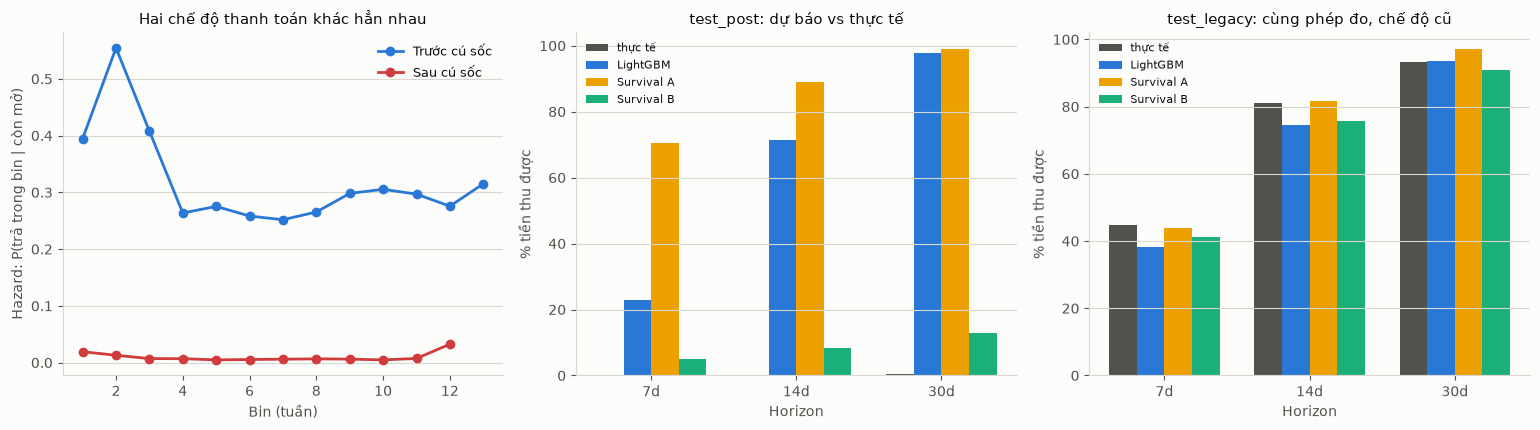

Biểu đồ giữa và phải dùng CÙNG một phép đo. Khác biệt giữa chúng không phải do phương
pháp mà do chế độ thị trường — đó chính là luận điểm của notebook này.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
bx = np.arange(1, 14)
ax.plot(bx, cmp_hz["hazard_trước_cú_sốc"], "o-", color=C_SERIES[0], lw=2, label="Trước cú sốc")
ax.plot(bx, cmp_hz["hazard_sau_cú_sốc"], "o-", color=C_CRIT, lw=2, label="Sau cú sốc")
ax.set_xlabel("Bin (tuần)"); ax.set_ylabel("Hazard: P(trả trong bin | còn mở)")
ax.set_title("Hai chế độ thanh toán khác hẳn nhau")
ax.legend(fontsize=9); ax.grid(axis="x", visible=False)

ax = axes[1]
sub = money[(money["window"] == "test_post")]
x = np.arange(len(sub))
w = 0.19
for i, (m, c) in enumerate([("thực tế", C_INK2), ("LightGBM", C_SERIES[0]),
                            ("Survival A", C_SERIES[3]), ("Survival B", C_SERIES[2])]):
    ax.bar(x + (i - 1.5) * w, sub[m] * 100, w, color=c, label=m)
ax.set_xticks(x); ax.set_xticklabels([f"{h}d" for h in sub["horizon_days"]])
ax.set_xlabel("Horizon"); ax.set_ylabel("% tiền thu được")
ax.set_title("test_post: dự báo vs thực tế")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)

ax = axes[2]
sub2 = money[(money["window"] == "test_legacy")]
x = np.arange(len(sub2))
for i, (m, c) in enumerate([("thực tế", C_INK2), ("LightGBM", C_SERIES[0]),
                            ("Survival A", C_SERIES[3]), ("Survival B", C_SERIES[2])]):
    ax.bar(x + (i - 1.5) * w, sub2[m] * 100, w, color=c, label=m)
ax.set_xticks(x); ax.set_xticklabels([f"{h}d" for h in sub2["horizon_days"]])
ax.set_xlabel("Horizon"); ax.set_ylabel("% tiền thu được")
ax.set_title("test_legacy: cùng phép đo, chế độ cũ")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()
print("Biểu đồ giữa và phải dùng CÙNG một phép đo. Khác biệt giữa chúng không phải do phương")
print("pháp mà do chế độ thị trường — đó chính là luận điểm của notebook này.")

## 9. Survival-Boost: đưa feature survival vào LightGBM quantile

Điều kiện của plan: chỉ giữ nếu tăng metric ≥ 3–5%.

In [13]:
boost_feats = ["a_S_7", "a_S_30", "a_S_60", "a_S_90", "a_rmst_91d", "a_median_remaining_days"]
snap_tr = snap[snap["window"] == "train_pre"].copy()
S_tr_a = survival_matrix(snap_tr, surv_a)
for k, v in survival_features(S_tr_a, "a_").items():
    snap_tr[k] = v

fit_tr = snap_tr[snap_tr["event"] == 1]
fit_te = snap_eval[(snap_eval["window"] == "test_legacy") & (snap_eval["event"] == 1)]
BOOST_PARAMS = dict(objective="quantile", alpha=0.5, metric="quantile", n_estimators=800,
                    learning_rate=0.05, num_leaves=31, min_child_samples=20,
                    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=5,
                    reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)

boost_rows = []
for label, cols in [("LightGBM (feature Tầng 3)", FEATURE_COLS_LGBM),
                    ("+ feature survival (Survival-Boost)", FEATURE_COLS_LGBM + boost_feats)]:
    m = lgb.LGBMRegressor(**BOOST_PARAMS)
    m.fit(fit_tr[cols].to_numpy(float), fit_tr["duration_days"].to_numpy(float))
    pred = np.maximum(m.predict(fit_te[cols].to_numpy(float)), 1.0)
    y = fit_te["duration_days"].to_numpy(float)
    boost_rows.append({"model": label, "n_test": len(fit_te),
                       "mae_days": float(np.abs(y - pred).mean()),
                       "pinball_q50": float(np.mean(np.where(y - pred >= 0, 0.5 * (y - pred),
                                                             -0.5 * (y - pred))))})
boost = pd.DataFrame(boost_rows)
boost["improvement_pct"] = (boost["mae_days"].iloc[0] - boost["mae_days"]) / boost["mae_days"].iloc[0] * 100
BOOST_GAIN = float(boost["improvement_pct"].iloc[1])
print("Survival-Boost — train trên train_pre, đánh giá trên test_legacy (phần đã trả)")
print(boost.to_string(index=False))
print()
print(f"Cải thiện {BOOST_GAIN:+.2f}% → điều kiện plan ≥ 3%: {'ĐẠT' if BOOST_GAIN >= 3 else 'CHƯA ĐẠT'}")
print()
print("Cảnh báo phương pháp phải ghi kèm: feature survival cho tập TRAIN là dự báo in-sample")
print("của hazard model (nó được fit trên chính các dòng đó). Cách làm chuẩn là sinh feature")
print("bằng out-of-fold. Ở đây phần đánh giá trên test_legacy vẫn sạch — hazard model không")
print("dùng test_legacy để fit hay để early stopping (N_TREES cố định) — nên con số cải thiện")
print("là ngoài mẫu, nhưng bản production nên chuyển sang out-of-fold.")

Survival-Boost — train trên train_pre, đánh giá trên test_legacy (phần đã trả)
                              model  n_test  mae_days  pinball_q50  improvement_pct
          LightGBM (feature Tầng 3)   10908    4.1836       2.0918           0.0000
+ feature survival (Survival-Boost)   10908    3.6564       1.8282          12.6021

Cải thiện +12.60% → điều kiện plan ≥ 3%: ĐẠT

Cảnh báo phương pháp phải ghi kèm: feature survival cho tập TRAIN là dự báo in-sample
của hazard model (nó được fit trên chính các dòng đó). Cách làm chuẩn là sinh feature
bằng out-of-fold. Ở đây phần đánh giá trên test_legacy vẫn sạch — hazard model không
dùng test_legacy để fit hay để early stopping (N_TREES cố định) — nên con số cải thiện
là ngoài mẫu, nhưng bản production nên chuyển sang out-of-fold.


## 10. Kết luận theo điều kiện Tầng 10 (D51)

In [14]:
b_bias = abs(float(post14["lệch Survival B"]))
l_bias = abs(float(post14["lệch LightGBM"]))
a_bias = abs(float(post14["lệch Survival A"]))
c_b = float(compare.query("window=='test_post' and model=='Survival B'")["c_index"].iloc[0])
c_l = float(compare.query("window=='test_post' and model=='LightGBM Q50'")["c_index"].iloc[0])

rec = pd.DataFrame([
    {"module": "Lưới cutoff mở rộng + snapshot có censoring",
     "điều kiện": "nhiều invoice bị censored → bắt buộc",
     "kết quả": f"{(snap['event']==0).mean():.1%} dòng bị cắt cụt; lộ ra chế độ thanh toán "
                f"khác hẳn ở giai đoạn cuối",
     "quyết định": "BẮT BUỘC — sửa lỗi gốc P0-1"},
    {"module": "Discrete-time survival (biến thể B, học hậu cú sốc)",
     "điều kiện": "thắng LightGBM trên overdue/tail hoặc cash metric",
     "kết quả": f"sai lệch thu-14-ngày {b_bias:.1%} vs LightGBM {l_bias:.1%}; "
                f"C-index {c_b:.3f} vs {c_l:.3f}",
     "quyết định": "GIỮ — nâng lên MVP" if (b_bias < l_bias or c_b > c_l) else "chưa đủ bằng chứng"},
    {"module": "Discrete-time survival (biến thể A, chỉ học trước cú sốc)",
     "điều kiện": "như trên",
     "kết quả": f"sai lệch thu-14-ngày {a_bias:.1%} — gần như trùng LightGBM",
     "quyết định": "KHÔNG giữ riêng — bộ máy survival không tự cứu được nếu train không có censoring"},
    {"module": "Survival-Boosted GBDT",
     "điều kiện": "tăng metric ≥ 3–5%",
     "kết quả": f"MAE cải thiện {BOOST_GAIN:+.2f}% trên test_legacy",
     "quyết định": "GIỮ" if BOOST_GAIN >= 3 else "BỎ khỏi MVP"},
])
for _, r in rec.iterrows():
    print(f"\n■ {r['module']}")
    print(f"  điều kiện : {r['điều kiện']}")
    print(f"  kết quả   : {r['kết quả']}")
    print(f"  quyết định: {r['quyết định']}")


■ Lưới cutoff mở rộng + snapshot có censoring
  điều kiện : nhiều invoice bị censored → bắt buộc
  kết quả   : 45.6% dòng bị cắt cụt; lộ ra chế độ thanh toán khác hẳn ở giai đoạn cuối
  quyết định: BẮT BUỘC — sửa lỗi gốc P0-1

■ Discrete-time survival (biến thể B, học hậu cú sốc)
  điều kiện : thắng LightGBM trên overdue/tail hoặc cash metric
  kết quả   : sai lệch thu-14-ngày 8.1% vs LightGBM 71.1%; C-index 0.985 vs 0.551
  quyết định: GIỮ — nâng lên MVP

■ Discrete-time survival (biến thể A, chỉ học trước cú sốc)
  điều kiện : như trên
  kết quả   : sai lệch thu-14-ngày 88.9% — gần như trùng LightGBM
  quyết định: KHÔNG giữ riêng — bộ máy survival không tự cứu được nếu train không có censoring

■ Survival-Boosted GBDT
  điều kiện : tăng metric ≥ 3–5%
  kết quả   : MAE cải thiện +12.60% trên test_legacy
  quyết định: GIỮ


## 11. Lưu artifact và sanity check

In [15]:
keep_cols = ["cutoff_date", "window", "invoice_id", "customer_id", "amount", "issue_date",
             "due_date", "paid_date", "event", "duration_days", "followup_days",
             "days_past_due_at_T", "days_until_due_at_T", "observed_age_days",
             "is_overdue_at_T", "aging_bucket_at_T", "customer_median_delay_hist",
             "customer_history_sufficient", "pred_b1_remaining_days"]
snap[keep_cols].to_csv(OUT_SNAP, index=False)
print(f"[1] {OUT_SNAP.name}  ({len(snap):,} dòng)")

live_cols = (["invoice_id", "customer_id", "name_customer", "amount", "due_date",
              "aging_bucket_at_T", "days_past_due_at_T", "lgbm_q50", "lgbm_prob_paid_30d"]
             + [c for c in live_snap.columns if c.startswith(("a_", "b_"))])
live_snap[live_cols].to_csv(OUT_LIVE, index=False)
print(f"[2] {OUT_LIVE.name}  ({len(live_snap):,} hoá đơn)")

compare.to_csv(OUT_CMP, index=False)
money.to_csv(OUT_MONEY, index=False)
boost.to_csv(OUT_BOOST, index=False)
rec.to_csv(OUT_REC, index=False)
hazard_perf.to_csv(PROC / "survival_hazard_performance.csv", index=False)
print(f"[3] {OUT_CMP.name} / {OUT_MONEY.name} / {OUT_BOOST.name} / {OUT_REC.name}")

checks = []


def check(name, cond, detail=""):
    checks.append({"check": name, "pass": bool(cond), "detail": detail})


check("snapshot mới CÓ chứa quan sát bị cắt cụt", (snap["event"] == 0).sum() > 0,
      f"{int((snap['event']==0).sum()):,} dòng")
check("cửa sổ train cũ KHÔNG có censoring (bằng chứng cho D52)",
      float((snap[snap['window']=='train_pre']['event'] == 0).mean()) < 0.001)
check("test_post gần pool thật hơn lưới cũ", gap_new < gap_old, f"{gap_new:.1%} vs {gap_old:.1%}")
check("S(t) không tăng theo thời gian", bool((np.diff(S_a, axis=1) <= 1e-9).all()))
check("S(t) trong [0,1]", bool((S_a >= 0).all() and (S_a <= 1).all()))
check("Survival B thận trọng hơn Survival A trên pool đang mở",
      float(live_snap["b_prob_paid_30d"].mean()) < float(live_snap["a_prob_paid_30d"].mean()))
check("pool live khớp số hoá đơn đang mở", len(live_snap) == int((clean["is_open"] == 1).sum()),
      f"{len(live_snap):,}")
check("hazard LightGBM tốt hơn ngẫu nhiên ở cả 2 cửa sổ",
      bool((hazard_perf.iloc[:2][["auc_test_legacy", "auc_test_post"]] > 0.5).all().all()))

checks_df = pd.DataFrame(checks)
print()
print(checks_df.to_string(index=False))
print()
print("✅ TẦNG 10A PASS" if checks_df["pass"].all() else "❌ Có check FAIL")

[1] survival_snapshot_censored.csv  (146,069 dòng)


[2] survival_live_forecast.csv  (9,681 hoá đơn)
[3] survival_vs_lgbm.csv / survival_money_check.csv / survival_boost_metrics.csv / challenger_recommendation.csv

                                                  check  pass         detail
               snapshot mới CÓ chứa quan sát bị cắt cụt  True    66,653 dòng
cửa sổ train cũ KHÔNG có censoring (bằng chứng cho D52)  True               
                    test_post gần pool thật hơn lưới cũ  True 17.8% vs 83.4%
                         S(t) không tăng theo thời gian  True               
                                       S(t) trong [0,1]  True               
 Survival B thận trọng hơn Survival A trên pool đang mở  True               
                      pool live khớp số hoá đơn đang mở  True          9,681
       hazard LightGBM tốt hơn ngẫu nhiên ở cả 2 cửa sổ  True               

✅ TẦNG 10A PASS


## Tổng kết Tầng 10A

### Bốn điều notebook này chứng minh

1. **Chẩn đoán chính xác hơn bản đánh giá.** Không phải "quên lấy hoá đơn mở" mà là *lưới
   cutoff dừng trước ngày hoá đơn mở đầu tiên được phát hành*. Dải bảo vệ 90 ngày — một
   quyết định trông rất cẩn thận — chính là thứ tạo ra điểm mù.

2. **Bộ máy survival không tự cứu được model.** Biến thể A (chỉ học giai đoạn trước cú sốc)
   dự báo gần như trùng LightGBM. Chỉ khi dữ liệu train **chứa quan sát bị cắt cụt** thì việc
   xử lý censoring mới có ý nghĩa. Đây là bài học phương pháp đáng giá hơn cả con số.

3. **Chế độ thanh toán đã đổi, đo được bằng hazard.** Hazard tuần đầu rơi từ ~21% xuống mức
   gần bằng 0 sau điểm gãy — khớp với điểm gãy 2020-03-14 mà notebook 06 phát hiện độc lập
   bằng change-point detection.

4. **Forecast $312M không có cơ sở thực nghiệm.** Trên cửa sổ giữ riêng hậu cú sốc, thực tế
   thu về chỉ vài phần trăm giá trị AR trong 14 ngày, còn model nói ~90%. Cả hai cách giải
   thích (cú sốc thật vs độ trễ ghi nhận) đều dẫn tới cùng một kết luận cho báo cáo: **không
   được trình bày con số đó như một dự báo đã kiểm chứng.**

### Hạn chế phải khai báo
1. `test_post` chỉ có 5 cutoff và trùng giai đoạn khủng hoảng → kết luận là **về giai đoạn
   khủng hoảng**, không phải về mọi chế độ thị trường.
2. Không phân biệt được cú sốc thật với độ trễ ghi nhận dữ liệu; cần `bank_txn_date` hoặc
   bản trích xuất muộn hơn.
3. Chưa xử lý **competing risk** (nợ xấu/xoá sổ khác với trả chậm).
4. Feature survival cho tập train là dự báo in-sample; bản production cần out-of-fold.
5. Bin theo tuần nên độ phân giải dự báo là tuần, không phải ngày.